# T15 - Find the Most Important Features

This notebook explains which of the 14 engineered features drive the hallucination predictions of the two tuned models from T12 (random forest and XGBoost). One importance method can be misleading, so we compare three:

1. **Built-in importance**: mean decrease in impurity (random forest) and gain (XGBoost). Fast, but computed on the training data and biased toward continuous features with many split points.
2. **Permutation importance on the test split**: how much ROC-AUC and F1 drop when a feature is shuffled. Model-agnostic and measured on unseen data. The six LLM one-hot columns and the three task-type columns are also shuffled **as groups**, because a single one-hot column only carries part of the information.
3. **SHAP values** (TreeExplainer): how much each feature pushes each prediction up or down, which also shows the **direction** of the effect.

Positive class: `hallucinated = 1`.

*AI-use disclosure: this notebook was drafted with the help of Claude Code (Anthropic) and reviewed by the author.*

## 1. Setup and data

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, f1_score
from xgboost import XGBClassifier

RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid')

project_root = next(
    p for p in [Path.cwd().resolve(), Path.cwd().resolve().parent]
    if (p / 'data' / 'processed' / 'features.csv').exists()
)
results_dir = project_root / 'results'

df = pd.read_csv(project_root / 'data' / 'processed' / 'features.csv')
exclude_cols = ['id', 'source_id', 'split', 'hallucinated']
feature_cols = [c for c in df.columns if c not in exclude_cols]

train_df = df[df['split'] == 'train'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)
X_train, y_train = train_df[feature_cols], train_df['hallucinated'].astype(int)
X_test, y_test = test_df[feature_cols], test_df['hallucinated'].astype(int)

print(f'Train: {len(X_train):,} rows | Test: {len(X_test):,} rows | Features: {len(feature_cols)}')

Train: 14,942 rows | Test: 2,675 rows | Features: 14


## 2. Rebuild the tuned T12 models

The best settings are read from `results/T12_cv_results.csv` (rank 1 for each model) and refit on the training split with the same random seed. We then check that the test probabilities match `results/predictions.csv`, so this analysis explains exactly the models that T17 and T18 use.

In [2]:
cv_results = pd.read_csv(results_dir / 'T12_cv_results.csv')
best = cv_results[cv_results['rank_test_score'] == 1].set_index('model')


def as_int_or_none(value):
    return None if pd.isna(value) else int(value)


rf_params = dict(
    n_estimators=int(best.loc['random_forest', 'n_estimators']),
    max_depth=as_int_or_none(best.loc['random_forest', 'max_depth']),
    min_samples_leaf=int(best.loc['random_forest', 'min_samples_leaf']),
)
xgb_params = dict(
    n_estimators=int(best.loc['xgboost', 'n_estimators']),
    max_depth=int(best.loc['xgboost', 'max_depth']),
    learning_rate=float(best.loc['xgboost', 'learning_rate']),
)
print('Random forest:', rf_params)
print('XGBoost:      ', xgb_params)

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1, **rf_params)),
]).fit(X_train, y_train)

xgb = Pipeline([
    ('model', XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                            scale_pos_weight=scale_pos_weight, subsample=0.8, colsample_bytree=0.8,
                            tree_method='hist', random_state=RANDOM_STATE, n_jobs=1, **xgb_params)),
]).fit(X_train, y_train)

models = {'random_forest': rf, 'xgboost': xgb}

saved = pd.read_csv(results_dir / 'predictions.csv')
for name, col in [('random_forest', 'prob_rf'), ('xgboost', 'prob_xgb')]:
    p = models[name].predict_proba(X_test)[:, 1]
    max_diff = np.abs(p - saved[col].values).max()
    print(f'{name}: test ROC-AUC {roc_auc_score(y_test, p):.4f}, '
          f'max difference vs. predictions.csv = {max_diff:.2e}')
    assert max_diff < 1e-4, f'{name} does not reproduce T12'

Random forest: {'n_estimators': 200, 'max_depth': 10, 'min_samples_leaf': 1}
XGBoost:       {'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.05}


random_forest: test ROC-AUC 0.8753, max difference vs. predictions.csv = 0.00e+00
xgboost: test ROC-AUC 0.8743, max difference vs. predictions.csv = 2.98e-08


## 3. Built-in importance

Random forest: mean decrease in Gini impurity. XGBoost: average gain of the splits that use each feature. Both are normalized to sum to 1. These scores come from the training data only.

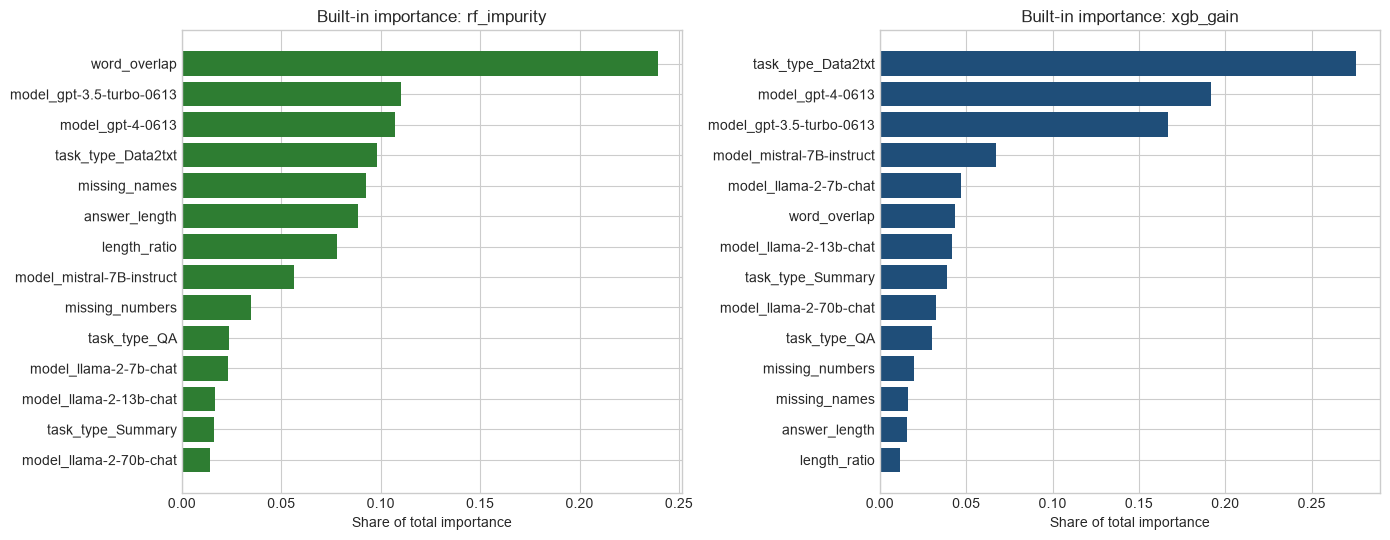

,rf_impurity,xgb_gain
word_overlap,0.240,0.043
model_gpt-3.5-turbo-0613,0.110,0.167
model_gpt-4-0613,0.107,0.192
task_type_Data2txt,0.098,0.276
missing_names,0.092,0.016
answer_length,0.089,0.016
length_ratio,0.078,0.012
model_mistral-7B-instruct,0.056,0.067
missing_numbers,0.035,0.020
task_type_QA,0.024,0.030


In [3]:
builtin = pd.DataFrame({
    'rf_impurity': rf.named_steps['model'].feature_importances_,
    'xgb_gain': pd.Series(xgb.named_steps['model'].get_booster().get_score(importance_type='gain'))
                  .reindex(feature_cols).fillna(0).values,
}, index=feature_cols)
builtin = builtin / builtin.sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, col, color in zip(axes, builtin.columns, ['#2e7d32', '#1f4e79']):
    s = builtin[col].sort_values()
    ax.barh(s.index, s.values, color=color)
    ax.set(title=f'Built-in importance: {col}', xlabel='Share of total importance')
plt.tight_layout()
plt.show()
builtin.sort_values('rf_impurity', ascending=False).round(3)

## 4. Permutation importance on the test split

Each feature is shuffled 20 times on the test split, and we record the average drop in ROC-AUC (threshold-free ranking quality) and in F1 at the 0.5 threshold (the metric used for tuning). A drop near zero means the model does not rely on that feature for unseen data.

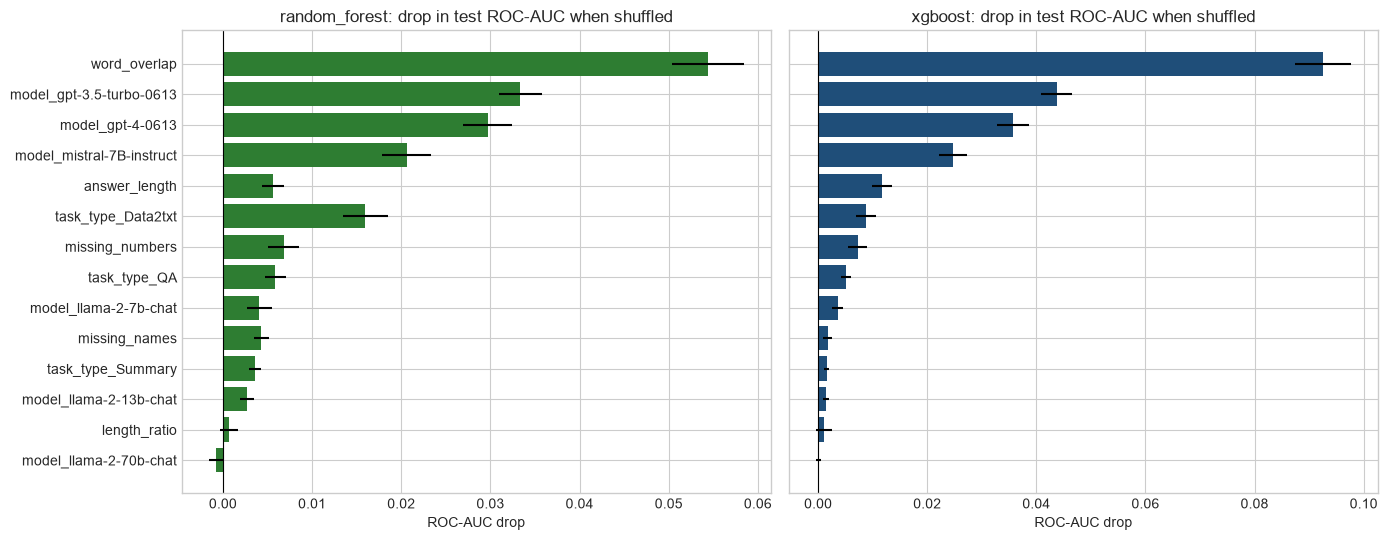

random_forest                                   \
                               auc_drop auc_drop_std f1_drop f1_drop_std   
word_overlap                     0.0544       0.0040  0.0570      0.0059   
model_gpt-3.5-turbo-0613         0.0333       0.0024  0.0367      0.0052   
model_gpt-4-0613                 0.0297       0.0028  0.0371      0.0048   
model_mistral-7B-instruct        0.0206       0.0028  0.0354      0.0046   
answer_length                    0.0056       0.0012  0.0079      0.0038   
task_type_Data2txt               0.0160       0.0025  0.0179      0.0051   
missing_numbers                  0.0068       0.0017  0.0081      0.0041   
task_type_QA                     0.0059       0.0012  0.0126      0.0030   
model_llama-2-7b-chat            0.0041       0.0014  0.0051      0.0030   
missing_names                    0.0043       0.0009  0.0067      0.0045   
task_type_Summary                0.0036       0.0007  0.0077      0.0028   
model_llama-2-13b-chat           0.0027       0.0008  0.0038      0.0024   
length_ratio                     0.0006       0.0010 -0.0015      0.0041   
model_llama-2-70b-chat          -0.0007       0.0009  0.0020      0.0022   

                           xgboost                                   
                          auc_drop auc_drop_std f1_drop f1_drop_std  
word_overlap                0.0925       0.0051  0.0996      0.0094  
model_gpt-3.5-turbo-0613    0.0437       0.0029  0.0428      0.0056  
model_gpt-4-0613            0.0358       0.0030  0.0428      0.0053  
model_mistral-7B-instruct   0.0247       0.0026  0.0302      0.0057  
answer_length               0.0118       0.0018  0.0136      0.0043  
task_type_Data2txt          0.0088       0.0018  0.0112      0.0032  
missing_numbers             0.0072       0.0018  0.0076      0.0031  
task_type_QA                0.0051       0.0009  0.0081      0.0021  
model_llama-2-7b-chat       0.0036       0.0010  0.0061      0.0024  
missing_names               0.0017       0.0008  0.0008      0.0038  
task_type_Summary           0.0016       0.0004  0.0025      0.0015  
model_llama-2-13b-chat      0.0014       0.0006  0.0003      0.0013  
length_ratio                0.0010       0.0015 -0.0025      0.0042  
model_llama-2-70b-chat      0.0001       0.0004 -0.0003      0.0016

In [4]:
N_REPEATS = 20
perm_tables = {}
for name, model in models.items():
    r = permutation_importance(model, X_test, y_test, scoring=['roc_auc', 'f1'],
                               n_repeats=N_REPEATS, random_state=RANDOM_STATE, n_jobs=-1)
    perm_tables[name] = pd.DataFrame({
        'auc_drop': r['roc_auc'].importances_mean, 'auc_drop_std': r['roc_auc'].importances_std,
        'f1_drop': r['f1'].importances_mean, 'f1_drop_std': r['f1'].importances_std,
    }, index=feature_cols)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
order = perm_tables['xgboost']['auc_drop'].sort_values().index
for ax, (name, t), color in zip(axes, perm_tables.items(), ['#2e7d32', '#1f4e79']):
    t = t.loc[order]
    ax.barh(t.index, t['auc_drop'], xerr=t['auc_drop_std'], color=color)
    ax.axvline(0, color='black', lw=0.8)
    ax.set(title=f'{name}: drop in test ROC-AUC when shuffled', xlabel='ROC-AUC drop')
plt.tight_layout()
plt.show()

pd.concat(perm_tables, axis=1).sort_values(('xgboost', 'auc_drop'), ascending=False).round(4)

### Grouped permutation importance

The LLM that wrote the answer is encoded as six one-hot columns and the task type as three. Shuffling one column at a time breaks the one-hot structure and splits the effect across columns, so here each group is shuffled **together** (the same row permutation for all its columns). This gives the importance of "which LLM" and "which task" as single factors, comparable with the five numeric features.

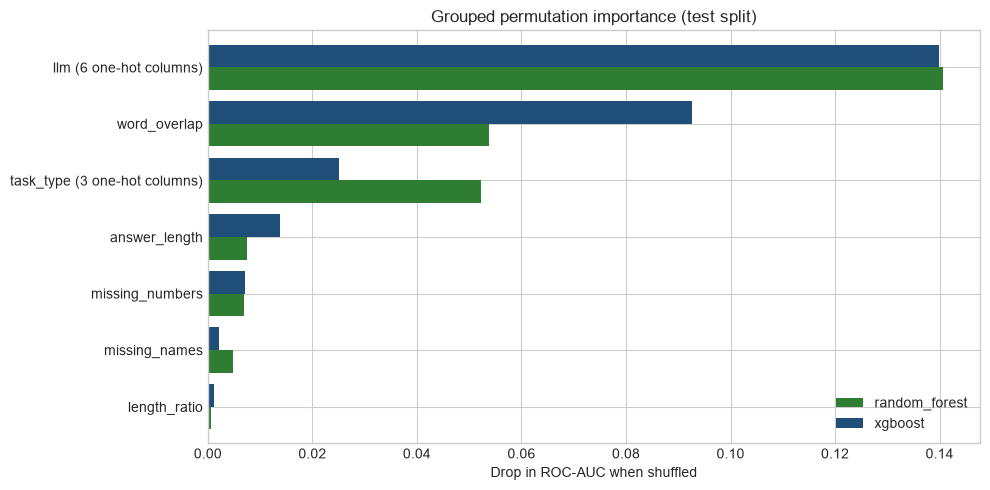

random_forest                                   \
                                   auc_drop auc_drop_std f1_drop f1_drop_std   
feature_group                                                                  
llm (6 one-hot columns)              0.1407       0.0061  0.1724      0.0081   
word_overlap                         0.0537       0.0045  0.0547      0.0071   
task_type (3 one-hot columns)        0.0522       0.0032  0.0631      0.0062   
answer_length                        0.0075       0.0017  0.0114      0.0056   
missing_numbers                      0.0068       0.0015  0.0079      0.0037   
missing_names                        0.0048       0.0014  0.0076      0.0038   
length_ratio                         0.0006       0.0010 -0.0003      0.0032   

                               xgboost                                   
                              auc_drop auc_drop_std f1_drop f1_drop_std  
feature_group                                                            
llm (6 one-hot columns)         0.1399       0.0062  0.1585      0.0088  
word_overlap                    0.0927       0.0058  0.0987      0.0065  
task_type (3 one-hot columns)   0.0250       0.0021  0.0331      0.0046  
answer_length                   0.0138       0.0025  0.0166      0.0042  
missing_numbers                 0.0070       0.0019  0.0077      0.0045  
missing_names                   0.0021       0.0012  0.0023      0.0037  
length_ratio                    0.0011       0.0016 -0.0027      0.0029

In [5]:
groups = {c: [c] for c in feature_cols if not c.startswith(('model_', 'task_type_'))}
groups['llm (6 one-hot columns)'] = [c for c in feature_cols if c.startswith('model_')]
groups['task_type (3 one-hot columns)'] = [c for c in feature_cols if c.startswith('task_type_')]


def grouped_permutation(model, X, y, groups, n_repeats=N_REPEATS, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base_p = model.predict_proba(X)[:, 1]
    base_auc, base_f1 = roc_auc_score(y, base_p), f1_score(y, base_p >= 0.5)
    rows = []
    for group, cols in groups.items():
        auc_drops, f1_drops = [], []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]
            p = model.predict_proba(Xp)[:, 1]
            auc_drops.append(base_auc - roc_auc_score(y, p))
            f1_drops.append(base_f1 - f1_score(y, p >= 0.5))
        rows.append({'feature_group': group, 'auc_drop': np.mean(auc_drops), 'auc_drop_std': np.std(auc_drops),
                     'f1_drop': np.mean(f1_drops), 'f1_drop_std': np.std(f1_drops)})
    return pd.DataFrame(rows).set_index('feature_group')


grouped = {name: grouped_permutation(m, X_test, y_test, groups) for name, m in models.items()}
grouped_df = pd.concat(grouped, axis=1).sort_values(('xgboost', 'auc_drop'), ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = pd.DataFrame({n: g['auc_drop'] for n, g in grouped.items()}).loc[grouped_df.index[::-1]]
plot_df.plot.barh(ax=ax, color=['#2e7d32', '#1f4e79'], width=0.8)
ax.set(title='Grouped permutation importance (test split)', xlabel='Drop in ROC-AUC when shuffled', ylabel='')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
grouped_df.round(4)

## 5. SHAP values: size and direction of each effect

SHAP decomposes each test prediction (in log-odds for XGBoost, in probability for the random forest) into one contribution per feature. In the beeswarm plot, each dot is one answer; its color is the feature value (red = high, blue = low) and its horizontal position is how much that feature pushed the prediction toward "hallucinated" (right) or "not hallucinated" (left).

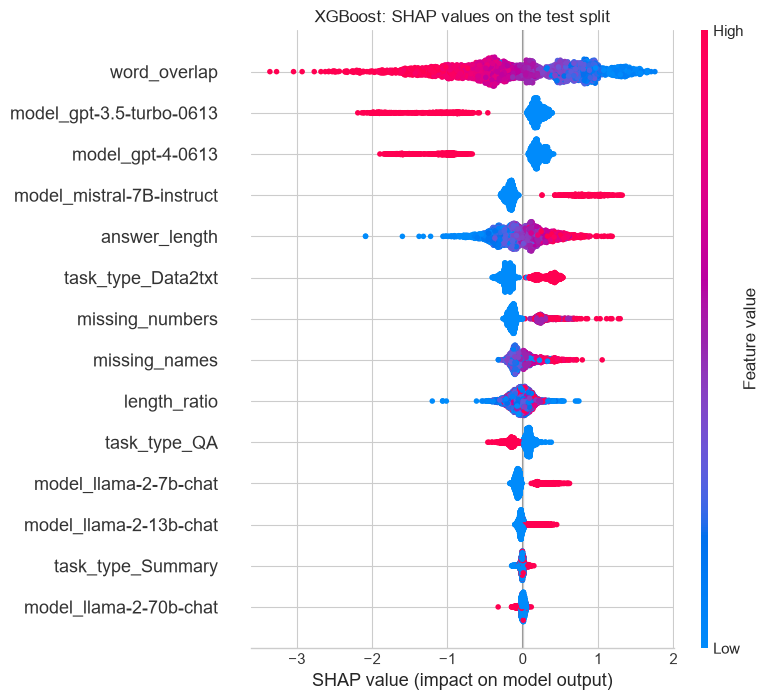

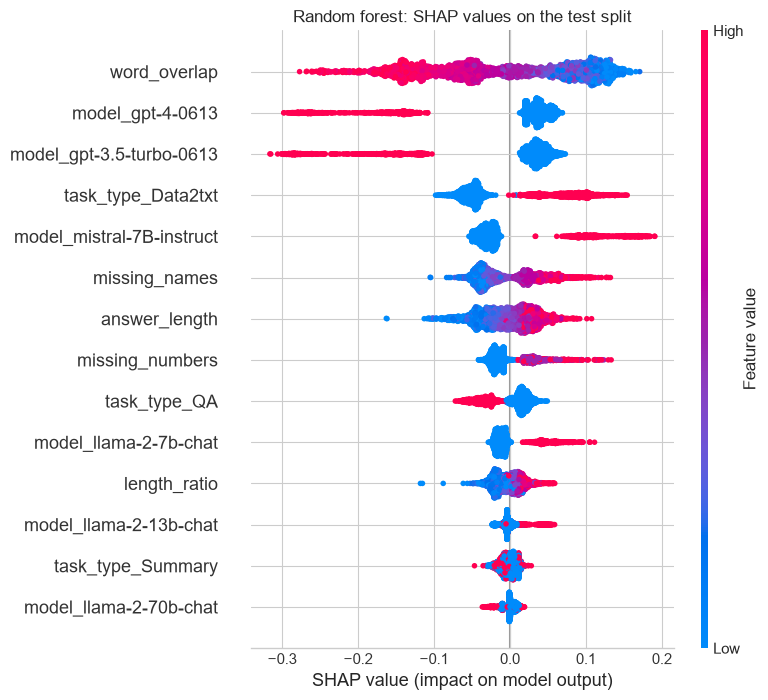

In [6]:
shap_values = {}

xgb_explainer = shap.TreeExplainer(xgb.named_steps['model'])
shap_values['xgboost'] = xgb_explainer(X_test)

rf_explainer = shap.TreeExplainer(rf.named_steps['model'])
rf_sv = rf_explainer(X_test, check_additivity=False)
shap_values['random_forest'] = rf_sv[:, :, 1]  # contributions to the hallucinated class

plt.figure()
shap.plots.beeswarm(shap_values['xgboost'], max_display=14, show=False)
plt.title('XGBoost: SHAP values on the test split')
plt.tight_layout()
plt.show()

plt.figure()
shap.plots.beeswarm(shap_values['random_forest'], max_display=14, show=False)
plt.title('Random forest: SHAP values on the test split')
plt.tight_layout()
plt.show()

### Direction of the effect

For each feature we report the mean |SHAP| (overall size) and the correlation between the feature value and its SHAP value: a positive sign means higher values raise the predicted hallucination risk. Correlations with |r| < 0.5 are labeled mixed/weak in the final table. The dependence plots show the shape of the effect for the four numeric features with the largest mean |SHAP| in XGBoost.

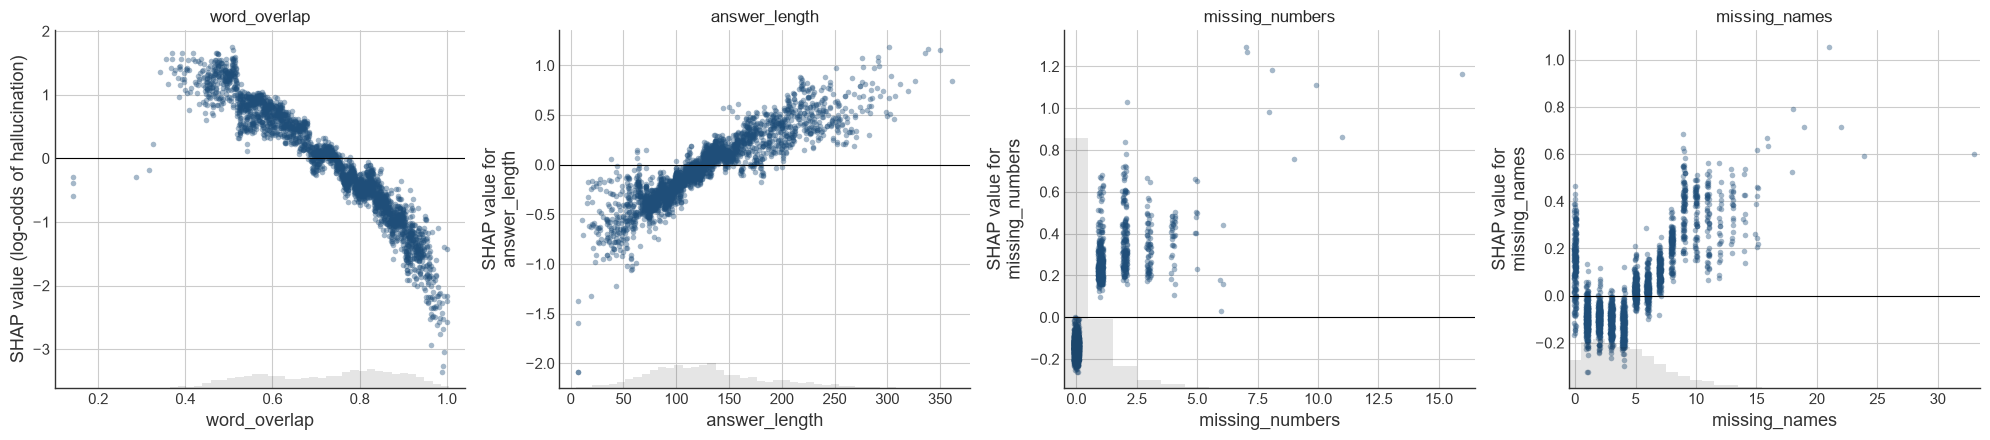

xgboost                 random_forest  \
                          mean_abs_shap value_shap_corr mean_abs_shap   
word_overlap                     0.7343         -0.9433        0.0916   
model_gpt-3.5-turbo-0613         0.3750         -0.9467        0.0625   
model_gpt-4-0613                 0.3723         -0.9653        0.0629   
model_mistral-7B-instruct        0.2834          0.9768        0.0452   
answer_length                    0.2737          0.8982        0.0292   
task_type_Data2txt               0.2540          0.9546        0.0599   
missing_numbers                  0.1892          0.8133        0.0240   
missing_names                    0.1290          0.6647        0.0363   
length_ratio                     0.1125          0.0643        0.0150   
task_type_QA                     0.1091         -0.9009        0.0231   
model_llama-2-7b-chat            0.1059          0.9367        0.0190   
model_llama-2-13b-chat           0.0549          0.8382        0.0088   
task_type_Summary                0.0222          0.3026        0.0078   
model_llama-2-70b-chat           0.0212         -0.5152        0.0064   

                                           
                          value_shap_corr  
word_overlap                      -0.9443  
model_gpt-3.5-turbo-0613          -0.9496  
model_gpt-4-0613                  -0.9559  
model_mistral-7B-instruct          0.9635  
answer_length                      0.8769  
task_type_Data2txt                 0.9502  
missing_numbers                    0.7337  
missing_names                      0.8997  
length_ratio                       0.7519  
task_type_QA                      -0.9271  
model_llama-2-7b-chat              0.9447  
model_llama-2-13b-chat             0.6458  
task_type_Summary                 -0.3283  
model_llama-2-70b-chat            -0.3474

In [7]:
def shap_summary(sv, X):
    vals = sv.values
    direction = [np.corrcoef(X[c], vals[:, i])[0, 1] if X[c].std() > 0 else np.nan
                 for i, c in enumerate(X.columns)]
    return pd.DataFrame({'mean_abs_shap': np.abs(vals).mean(axis=0), 'value_shap_corr': direction},
                        index=X.columns)


shap_tables = {name: shap_summary(sv, X_test) for name, sv in shap_values.items()}
shap_df = pd.concat(shap_tables, axis=1).sort_values(('xgboost', 'mean_abs_shap'), ascending=False)

numeric = [c for c in shap_df.index if not c.startswith(('model_', 'task_type_'))][:4]
fig, axes = plt.subplots(1, len(numeric), figsize=(5 * len(numeric), 4.5))
for ax, feat in zip(axes, numeric):
    shap.plots.scatter(shap_values['xgboost'][:, feat], ax=ax, show=False, color='#1f4e79', alpha=0.4)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(feat)
axes[0].set_ylabel('SHAP value (log-odds of hallucination)')
plt.tight_layout()
plt.show()
shap_df.round(4)

## 6. Combined ranking

Each method gives a rank per feature (1 = most important). The final ranking is the **average rank** across the six scores: built-in, permutation ROC-AUC drop, and mean |SHAP|, for both models. Agreement across methods is the main evidence that a feature truly matters.

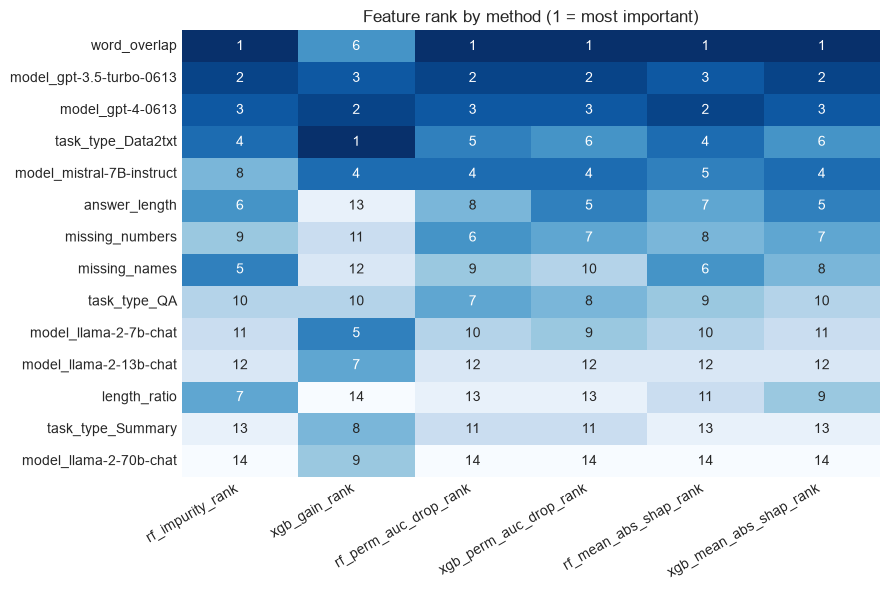

,mean_rank,direction,rf_perm_auc_drop,xgb_perm_auc_drop,xgb_mean_abs_shap
feature,,,,,
word_overlap,1.8333,higher -> less hallucination,0.0544,0.0925,0.7343
model_gpt-3.5-turbo-0613,2.3333,higher -> less hallucination,0.0333,0.0437,0.3750
model_gpt-4-0613,2.6667,higher -> less hallucination,0.0297,0.0358,0.3723
task_type_Data2txt,4.3333,higher -> more hallucination,0.0160,0.0088,0.2540
model_mistral-7B-instruct,4.8333,higher -> more hallucination,0.0206,0.0247,0.2834
answer_length,7.3333,higher -> more hallucination,0.0056,0.0118,0.2737
missing_numbers,8.0000,higher -> more hallucination,0.0068,0.0072,0.1892
missing_names,8.3333,higher -> more hallucination,0.0043,0.0017,0.1290
task_type_QA,9.0000,higher -> less hallucination,0.0059,0.0051,0.1091


In [8]:
scores = pd.DataFrame({
    'rf_impurity': builtin['rf_impurity'],
    'xgb_gain': builtin['xgb_gain'],
    'rf_perm_auc_drop': perm_tables['random_forest']['auc_drop'],
    'xgb_perm_auc_drop': perm_tables['xgboost']['auc_drop'],
    'rf_mean_abs_shap': shap_tables['random_forest']['mean_abs_shap'],
    'xgb_mean_abs_shap': shap_tables['xgboost']['mean_abs_shap'],
})
ranks = scores.rank(ascending=False).add_suffix('_rank')
summary = pd.concat([scores, ranks], axis=1)
summary['mean_rank'] = ranks.mean(axis=1)
corr = shap_tables['xgboost']['value_shap_corr']
summary['direction'] = np.select([corr >= 0.5, corr <= -0.5],
                                 ['higher -> more hallucination', 'higher -> less hallucination'],
                                 'mixed / weak (|corr| < 0.5)')
summary = summary.sort_values('mean_rank')
summary.index.name = 'feature'

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(ranks.loc[summary.index], annot=True, fmt='.0f', cmap='Blues_r', cbar=False, ax=ax)
ax.set(title='Feature rank by method (1 = most important)', xlabel='', ylabel='')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

summary[['mean_rank', 'direction', 'rf_perm_auc_drop', 'xgb_perm_auc_drop', 'xgb_mean_abs_shap']].round(4)

## 7. Save results

In [9]:
summary.to_csv(results_dir / 'T15_feature_importance.csv')
grouped_df.columns = [f'{m}_{c}' for m, c in grouped_df.columns]
grouped_df.to_csv(results_dir / 'T15_grouped_permutation_importance.csv')
print('Saved results/T15_feature_importance.csv and results/T15_grouped_permutation_importance.csv')

Saved results/T15_feature_importance.csv and results/T15_grouped_permutation_importance.csv


## 8. Conclusion

The summary below is computed from the results above, so it stays correct if the notebook is rerun.

In [10]:
print('Top 5 features by average rank across the six scores:')
for i, (feat, r) in enumerate(summary.head(5).iterrows(), 1):
    print(f"  {i}. {feat:28s} mean rank {r['mean_rank']:.1f}  ({r['direction']})")

g = pd.read_csv(results_dir / 'T15_grouped_permutation_importance.csv', index_col=0)
print('\nGrouped permutation importance (drop in test ROC-AUC, XGBoost / random forest):')
for feat, r in g.iterrows():
    print(f"  {feat:30s} {r['xgboost_auc_drop']:.4f} / {r['random_forest_auc_drop']:.4f}")

weak = summary[(summary['rf_perm_auc_drop'] < 0.002) & (summary['xgb_perm_auc_drop'] < 0.002)].index.tolist()
print(f'\nFeatures with a test ROC-AUC drop below 0.002 in both models: {weak}')

Top 5 features by average rank across the six scores:
  1. word_overlap                 mean rank 1.8  (higher -> less hallucination)
  2. model_gpt-3.5-turbo-0613     mean rank 2.3  (higher -> less hallucination)
  3. model_gpt-4-0613             mean rank 2.7  (higher -> less hallucination)
  4. task_type_Data2txt           mean rank 4.3  (higher -> more hallucination)
  5. model_mistral-7B-instruct    mean rank 4.8  (higher -> more hallucination)

Grouped permutation importance (drop in test ROC-AUC, XGBoost / random forest):
  llm (6 one-hot columns)        0.1399 / 0.1407
  word_overlap                   0.0927 / 0.0537
  task_type (3 one-hot columns)  0.0250 / 0.0522
  answer_length                  0.0138 / 0.0075
  missing_numbers                0.0070 / 0.0068
  missing_names                  0.0021 / 0.0048
  length_ratio                   0.0011 / 0.0006

Features with a test ROC-AUC drop below 0.002 in both models: ['length_ratio', 'model_llama-2-70b-chat']
